<a href="https://colab.research.google.com/github/teja2310/wireless-wanderlust/blob/main/task1_new.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import json
import os

training_set_labeled = [
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf02.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf02.json"
    },
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf03.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf03.json"
    }
]
training_set_unlabeled = [
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf04.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf04.json"
    },
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf05.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf05.json"
    },
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf07.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf07.json"
    }
]
test_set = [
    {
        "tfrecords": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\dichasus\dichasus-cf06.tfrecords",
        "offsets": r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\cf06.json"
    }
]

RAW_SUBCARRIER_COUNT = 1024
antenna_count = 0
array_positions = []
array_normalvectors = []
array_upvectors = []
array_rightvectors = []
antenna_assignments = []

# Load antennas and their details
with open(r"C:\Users\myg\Desktop\wireless-wanderlust-internship\offsets\spec.json") as specfile:
    spec = json.load(specfile)
    for antenna in spec["antennas"]:
        antenna_count = antenna_count + sum([len(row) for row in antenna["assignments"]])
        antenna_assignments.append(antenna["assignments"])

        array_positions.append(np.asarray(antenna["location"]))
        array_upvectors.append(np.asarray(antenna["upvector"]))
        array_rightvectors.append(np.asarray(antenna["rightvector"]))

        normalvector = np.cross(np.asarray(antenna["rightvector"]), np.asarray(antenna["upvector"]))
        normalvector = normalvector / np.linalg.norm(normalvector)
        array_normalvectors.append(normalvector)

# Define the parsing and calibration functions
def parse_and_calibrate(path, offset_path):
    offsets = None
    with open(offset_path, "r") as offsetfile:
        offsets = json.load(offsetfile)

    def record_parse_function(proto):
        record = tf.io.parse_single_example(
            proto,
            {
                "csi": tf.io.FixedLenFeature([], tf.string, default_value=""),
                "pos-tachy": tf.io.FixedLenFeature([], tf.string, default_value=""),
                "time": tf.io.FixedLenFeature([], tf.float32, default_value=0),
            },
        )

        # Normalize sampling time offset for CSI
        csi = tf.ensure_shape(tf.io.parse_tensor(record["csi"], out_type=tf.float32), (antenna_count, RAW_SUBCARRIER_COUNT, 2))
        csi = tf.complex(csi[:, :, 0], csi[:, :, 1])
        print("Shape of CSI after complex conversion:", csi.shape)

        csi = tf.signal.fftshift(csi, axes=1)
        print("Shape of CSI after fftshift:", csi.shape)

        incr = tf.cast(tf.math.angle(tf.math.reduce_sum(csi[:, 1:] * tf.math.conj(csi[:, :-1]))), tf.complex64)
        csi = csi * tf.exp(-1.0j * incr * tf.cast(tf.range(csi.shape[-1]), tf.complex64))[tf.newaxis, :]
        print("Shape of CSI after phase adjustment:", csi.shape)

        position = tf.ensure_shape(tf.io.parse_tensor(record["pos-tachy"], out_type=tf.float64), (3))
        print("Shape of Position:", position.shape)

        time = tf.ensure_shape(record["time"], ())
        print("Shape of Time:", time.shape)

        return csi, position, time

    def apply_calibration(csi, pos, time):
        sto_offset = tf.tensordot(
            tf.constant(offsets["sto"]),
            2 * np.pi * tf.range(tf.shape(csi)[1], dtype=np.float32) / tf.cast(tf.shape(csi)[1], np.float32),
            axes=0,
        )
        cpo_offset = tf.tensordot(
            tf.constant(offsets["cpo"]),
            tf.ones(tf.shape(csi)[1], dtype=np.float32),
            axes=0,
        )
        csi = tf.multiply(csi, tf.exp(tf.complex(0.0, sto_offset + cpo_offset)))
        print("Shape of CSI after calibration:", csi.shape)

        return csi, pos, time

    def shrink_csi(target_subcarrier_count=64):
        def compression(csi, pos, time):
            csi_tdomain = tf.signal.fftshift(tf.signal.ifft(tf.signal.fftshift(csi, axes=-1)), axes=-1)
            csi_tdomain_compressed = csi_tdomain[..., RAW_SUBCARRIER_COUNT // 2 - target_subcarrier_count // 2 : RAW_SUBCARRIER_COUNT // 2 + target_subcarrier_count // 2]
            print("Shape of CSI after compression:", csi_tdomain_compressed.shape)

            return tf.signal.fftshift(tf.signal.fft(tf.signal.fftshift(csi_tdomain_compressed, axes=-1)), axes=-1), pos, time

        return compression

    def order_by_antenna_assignments(csi, pos, time):
        print("Shape before reordering:", csi.shape)  # Expected: (32, 64, 2)

        reordered = []
        for array in antenna_assignments:  # 4 arrays
            array_csi = []
            for row in array:  # each row = 4 antenna indices
                gathered = tf.gather(csi, row, axis=0)  # shape: (4, 64, 2)
                array_csi.append(gathered)
            # array_csi: 2 blocks of (4, 64, 2) → concat → (8, 64, 2)
            array_csi = tf.concat(array_csi, axis=0)
            reordered.append(array_csi)

        # reordered: list of 4 tensors of shape (8, 64, 2)
        csi = tf.stack(reordered, axis=0)  # (4, 8, 64, 2)

        print("Shape after reordering:", csi.shape)
        return csi, pos, time

    def split_real_imag(csi, pos, time):
        csi = tf.stack([tf.math.real(csi), tf.math.imag(csi)], axis=-1)  # shape: (4, 8, 64, 2)
        print("Shape after splitting real and imag:", csi.shape)
        return csi, pos, time




    dset = tf.data.TFRecordDataset(path)
    dset = dset.map(record_parse_function)
    dset = dset.map(apply_calibration)
    dset = dset.map(shrink_csi())
    dset = dset.map(order_by_antenna_assignments)
    dset = dset.map(split_real_imag)
    return dset

def load_datasets(paths_list):
    full_dataset = parse_and_calibrate(paths_list[0]["tfrecords"], paths_list[0]["offsets"])

    for path in paths_list[1:]:
        full_dataset = full_dataset.concatenate(parse_and_calibrate(path["tfrecords"], path["offsets"]))

    return full_dataset.shard(4, 0)

# You may access the following variables for training
array_positions = np.asarray(array_positions)
array_normalvectors = np.asarray(array_normalvectors)
array_upvectors = np.asarray(array_upvectors)
array_rightvectors = np.asarray(array_rightvectors)
training_set_labeled = load_datasets(training_set_labeled)
training_set_unlabeled = load_datasets(training_set_unlabeled).map(lambda csi, pos, time: (csi, time))
test_set = load_datasets(test_set)


Shape of CSI after complex conversion: (32, 1024)
Shape of CSI after fftshift: (32, 1024)
Shape of CSI after phase adjustment: (32, 1024)
Shape of Position: (3,)
Shape of Time: ()
Shape of CSI after calibration: (32, 1024)
Shape of CSI after compression: (32, 64)
Shape before reordering: (32, 64)
Shape after reordering: (4, 8, 64)
Shape after splitting real and imag: (4, 8, 64, 2)
Shape of CSI after complex conversion: (32, 1024)
Shape of CSI after fftshift: (32, 1024)
Shape of CSI after phase adjustment: (32, 1024)
Shape of Position: (3,)
Shape of Time: ()
Shape of CSI after calibration: (32, 1024)
Shape of CSI after compression: (32, 64)
Shape before reordering: (32, 64)
Shape after reordering: (4, 8, 64)
Shape after splitting real and imag: (4, 8, 64, 2)
Shape of CSI after complex conversion: (32, 1024)
Shape of CSI after fftshift: (32, 1024)
Shape of CSI after phase adjustment: (32, 1024)
Shape of Position: (3,)
Shape of Time: ()
Shape of CSI after calibration: (32, 1024)
Shape of 

In [ ]:
import matplotlib.pyplot as plt
def load_data(tf_dataset, labeled = False):
    """
    Loads dataset from TensorFlow dataset to dictionary of NumPy arrays (might be more convenient)
    """
    data_dict = {
        "csi" : [],
        "time" : []
    }

    if labeled:
        data_dict["pos"] = []

    for datapoint in tf_dataset.batch(256):
        data_dict["csi"].append(datapoint[0].numpy())
        if labeled:
            data_dict["pos"].append(datapoint[1].numpy() if labeled else datapoint[0].numpy())
        data_dict["time"].append(datapoint[2].numpy() if labeled else datapoint[1].numpy())

    data_dict["csi"] = np.concatenate(data_dict["csi"])
    if labeled:
        data_dict["pos"] = np.concatenate(data_dict["pos"])
    data_dict["time"] = np.concatenate(data_dict["time"])

    return data_dict

In [ ]:

training_data_labeled_np = load_data(training_set_labeled, labeled = True)
training_data_unlabeled_np = load_data(training_set_unlabeled)
test_data_np = load_data(test_set, labeled = True)


In [ ]:
from tensorflow.keras import layers, models, optimizers, losses

def build_mae_3d(input_shape=(4,8,16,2)):
    inp = layers.Input(shape=input_shape)

    # conv block 1
    x = layers.Conv3D(
        filters=32,
        kernel_size=3,
        strides=(1,1,1),
        padding='same',
        activation='relu'
    )(inp)
    x = layers.MaxPool3D((1,2,2))(x)

    # conv block 2
    x = layers.Conv3D(
        filters=64,
        kernel_size=3,
        strides=(1,1,1),
        padding='same',
        activation='relu'
    )(x)
    x = layers.MaxPool3D((1,2,2))(x)

    # conv block 3
    x = layers.Conv3D(
        filters=128,
        kernel_size=3,
        strides=(1,1,1),
        padding='same',
        activation='relu'
    )(x)

    # latent
    lat = layers.GlobalAveragePooling3D(name='latent_vector')(x)

    # decoder
    x = layers.Reshape((1,1,1,128))(lat)
    x = layers.Conv3DTranspose(
        filters=128,
        kernel_size=(4,1,1),
        strides=(4,1,1),
        padding='same',
        activation='relu'
    )(x)
    x = layers.Conv3DTranspose(
        filters=64,
        kernel_size=(1,2,2),
        strides=(1,2,2),
        padding='same',
        activation='relu'
    )(x)
    x = layers.Conv3DTranspose(
        filters=32,
        kernel_size=(1,2,2),
        strides=(1,2,2),
        padding='same',
        activation='relu'
    )(x)
    x = layers.Conv3DTranspose(
        filters=16,
        kernel_size=(1,2,4),
        strides=(1,2,4),
        padding='same',
        activation='relu'
    )(x)
    out = layers.Conv3DTranspose(
        filters=2,
        kernel_size=(1,1,4),
        strides=(1,1,4),
        padding='same',
        activation='linear'
    )(x)

    return models.Model(inp, out, name='mae_csi')


def build_loc_model(mae_model):
    inp = mae_model.input
    lat = mae_model.get_layer('latent_vector').output

    x = layers.Dense(256, activation='relu')(lat)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    out = layers.Dense(3, activation='linear')(x)

    return models.Model(inp, out, name='loc_model')


In [ ]:
# UNPACK NUMPY DATA
X_lab, y_lab   = training_data_labeled_np['csi'], training_data_labeled_np['pos']
X_unl          = training_data_unlabeled_np['csi']
X_tst, y_tst   = test_data_np['csi'], test_data_np['pos']

# PRETRAIN MAE AUTOENCODER
mae_model = build_mae_3d(input_shape=X_unl.shape[1:])
mae_model.compile(optimizer='adam', loss='mse')
mae_model.fit(X_unl, X_unl, epochs=50, batch_size=32, validation_split=0.1)

# SUPERVISED WARM-UP
loc_model = build_loc_model(mae_model)
loc_model.compile(optimizer='adam', loss='mae')
loc_model.fit(X_lab, y_lab, epochs=50, batch_size=32, validation_split=0.1)

# PSEUDO-LABEL LOOP
opt    = optimizers.Adam(1e-4)
mae_fn = losses.MeanAbsoluteError()

for epoch in range(1, 101):
    pw = min(1.0, epoch/10)
    il = np.random.permutation(len(X_lab))
    iu = np.random.permutation(len(X_unl))

    sup_loss = 0.0
    pseudo_loss = 0.0

    for i in range(0, len(il), 32):
        xb = X_lab[il[i:i+32]]
        yb = y_lab[il[i:i+32]]
        xu = X_unl[iu[i:i+32]]

        with tf.GradientTape() as tape:
            Ls = mae_fn(yb, loc_model(xb, training=True))
            pseudo_lbls = loc_model(xu, training=False)
            Lu = mae_fn(pseudo_lbls, loc_model(xu, training=True))
            loss = Ls + pw*Lu

        grads = tape.gradient(loss, loc_model.trainable_weights)
        opt.apply_gradients(zip(grads, loc_model.trainable_weights))

        sup_loss    += Ls.numpy()
        pseudo_loss += Lu.numpy()

    print(f"Epoch {epoch:03d}: sup={sup_loss:.4f}, pseudo={pseudo_loss:.4f}, pw={pw:.2f}")
loc_model.save("best_loc_model.h5")

Epoch 1/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - loss: 5.7441 - val_loss: 2.8137
Epoch 2/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 3.1475 - val_loss: 2.0725
Epoch 3/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 2.4190 - val_loss: 1.7472
Epoch 4/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 2.1225 - val_loss: 1.6133
Epoch 5/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 1.9106 - val_loss: 1.4886
Epoch 6/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - loss: 1.7559 - val_loss: 1.4482
Epoch 7/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - loss: 1.6385 - val_loss: 1.3382
Epoch 8/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - loss: 1.5453 - val_loss: 1.2727
Epoch 9/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 1.4594 - val_loss: 1.2223
Epoch 10/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 1.3838 - val_loss: 1.1739
Epoch 11/50
867/867 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - loss: 1.3186 - val_loss: 1.1336
Epoch 12/50
867/867 ━━━━━━━━━━

Epoch 100: sup=18.5816, pseudo=15.2805, pw=1.00


54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
MAE: 0.2508, R90: 0.4526


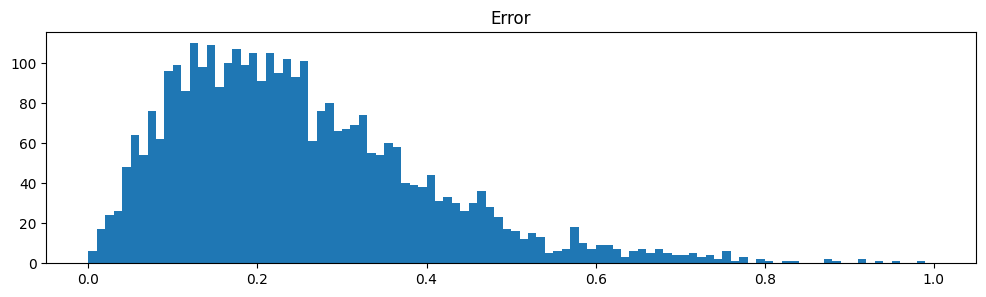

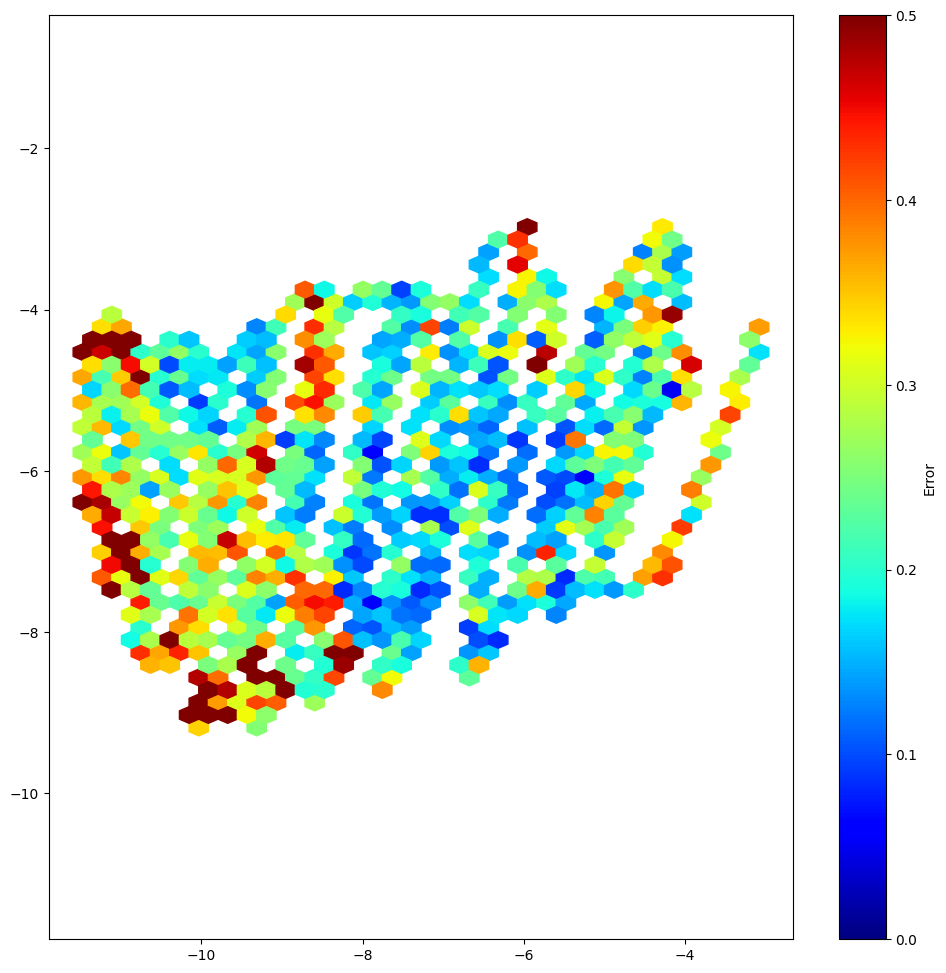

In [ ]:
# EVALUATION\
import matplotlib.cm as cm

preds = loc_model.predict(X_tst, batch_size=64)
errs  = np.linalg.norm( y_tst - preds, axis=1)
print(f"MAE: {errs.mean():.4f}, R90: {np.percentile(errs,90):.4f}")

plt.figure(figsize=(12,3))
plt.hist(errs, bins=100, range=(0,1))
plt.title('Error')
plt.show()

plt.figure(figsize=(12,12))
plt.hexbin(y_tst[:,0], y_tst[:,1], C=errs, gridsize=35, cmap=cm.jet, vmin=0, vmax=0.5)
plt.axis('equal')
plt.colorbar(label='Error')
plt.show()

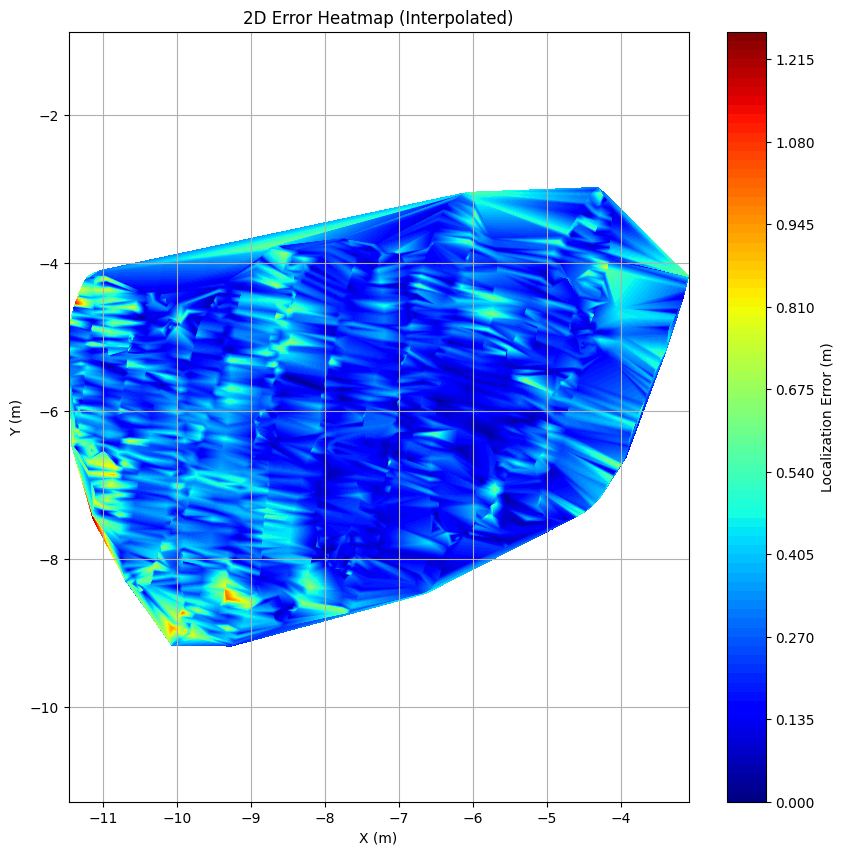

In [ ]:
import matplotlib.tri as tri

triang = tri.Triangulation(y_tst[:,0], y_tst[:,1])
plt.figure(figsize=(10,10))
plt.tricontourf(triang, errs, levels=100, cmap='jet')
plt.colorbar(label='Localization Error (m)')
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("2D Error Heatmap (Interpolated)")
plt.axis('equal')
plt.grid(True)
plt.show()
